# Demo 2: the manuscript's results

Every table and figure the manuscript reports for Demo 2, drawn from the forecast
ensembles. `01-model-and-forecast.ipynb` shows the models and one forecast; this is that
forecast repeated at all 24 weekly forecast dates, at two ensemble seeds, and scored.

Nothing here fits a model. The ensembles come from `scripts/run-demos.sh` (hours), and
`scripts/build-figures.sh` writes these same tables and figures to `results/demos/` from
the same functions, so this notebook and the paper cannot disagree.

| model | structure |
|---|---|
| `movement` | 32 counties, with commuting between them |
| `county` | the same 32 counties, nobody moves |
| `state` | 3 states, no spatial structure within a state |

All three are **scored at the 3 states**: the county models' counties are summed to states
within each realization before any quantile is taken, because quantiles do not add.

## Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from manuscript_analysis.demos import export, tables
from manuscript_analysis.demos.covid import evaluation
from manuscript_analysis.demos.lib.figures import use_manuscript_style

use_manuscript_style()
pd.set_option("display.width", 200)

## Load and score

Seed 0 is the manuscript run and seed 1 its replicate; both are scored against the one
frozen observations file. Scores are log WIS, as in CDC's FluSight evaluations, and the
skill table also reports the natural scale. A hospital census and a death count are not
commensurate, so every score is per quantity.

In [2]:
ev = evaluation.load()
replicate = evaluation.load_replicate()
natural = evaluation.load(scale="natural")

first, last = (pd.Timestamp(d).date() for d in (ev.origins[0], ev.origins[-1]))
print(f"{len(ev.origins)} forecast dates, {first} to {last}; "
      f"horizons {list(ev.horizons)}; scored at "
      f"{[ev.labels[code] for code in ev.locations]}")

24 forecast dates, 2020-10-04 to 2021-03-14; horizons [0, 1, 2, 3]; scored at ['CT', 'MA', 'NH']


In [3]:
# The models must differ ONLY in structure, or the comparison is not controlled.
for label, loaded in (("seed 0", ev), ("seed 1", replicate)):
    settings = {
        name: tuple(run.info[k] for k in ("season", "season_start", "season_weeks",
                                          "num_realizations", "burn_in_weeks",
                                          "horizon_weeks", "seed"))
        for name, run in loaded.runs.items()
    }
    assert len(set(settings.values())) == 1, f"{label}: models were not run identically"
    print(f"{label}: all {len(settings)} models run identically "
          f"(R = {next(iter(settings.values()))[3]})")

seed 0: all 3 models run identically (R = 600)
seed 1: all 3 models run identically (R = 600)


## Tables

**`covid-skill`**: forecast skill by model and quantity, both scales, with coverage.

In [4]:
tables.covid_skill(ev, natural)

WIS  rel WIS  log WIS  rel log WIS  cov95  cov50
model                 quantity                                                             
counties + commuting  hospital census   97.910    1.106    0.159        1.079  0.753  0.295
                      weekly deaths     18.931    1.028    0.160        0.997  0.872  0.385
counties, no movement hospital census  107.348    1.163    0.167        1.123  0.774  0.288
                      weekly deaths     20.171    1.058    0.165        1.018  0.844  0.382
no spatial structure  hospital census   76.412    1.000    0.136        1.000  1.000  0.510
                      weekly deaths     15.828    1.000    0.152        1.000  0.958  0.552

**`covid-reproducibility`**: relative log WIS at both seeds.

In [5]:
tables.covid_reproducibility(ev, replicate)

,,"rel log WIS, seed 0","rel log WIS, seed 1",geometric mean
model,quantity,,,
counties + commuting,hospital census,1.079,1.115,1.097
"counties, no movement",hospital census,1.123,1.146,1.134
counties + commuting,weekly deaths,0.997,1.019,1.008
"counties, no movement",weekly deaths,1.018,1.064,1.041


**`covid-by-state`**: the three scored states, with the movement contrast.

In [6]:
tables.covid_by_state(ev)

counties + commuting  counties, no movement  no spatial structure  movement / state  county / state  movement / county
jurisdiction quantity                                                                                                                               
CT           hospital census                 0.137                  0.144                 0.118             1.103           1.161              0.949
             weekly deaths                   0.141                  0.140                 0.119             1.086           1.057              1.027
MA           hospital census                 0.124                  0.131                 0.103             1.050           1.090              0.964
             weekly deaths                   0.106                  0.114                 0.110             0.865           0.912              0.949
NH           hospital census                 0.215                  0.227                 0.187             1.085           1.118              0.970
             weekly deaths                   0.233                  0.241                 0.228             1.055           1.097              0.962

## Figures

`export` composes these from panel functions in `covid/evaluation.py`. They display here
but are written to `results/demos/figures/` only by `scripts/build-figures.sh`.

**Figure 3**: the commuting matrix, skill by horizon, the fit at three counties, and the
per-county ratio of movement to no movement at both seeds.

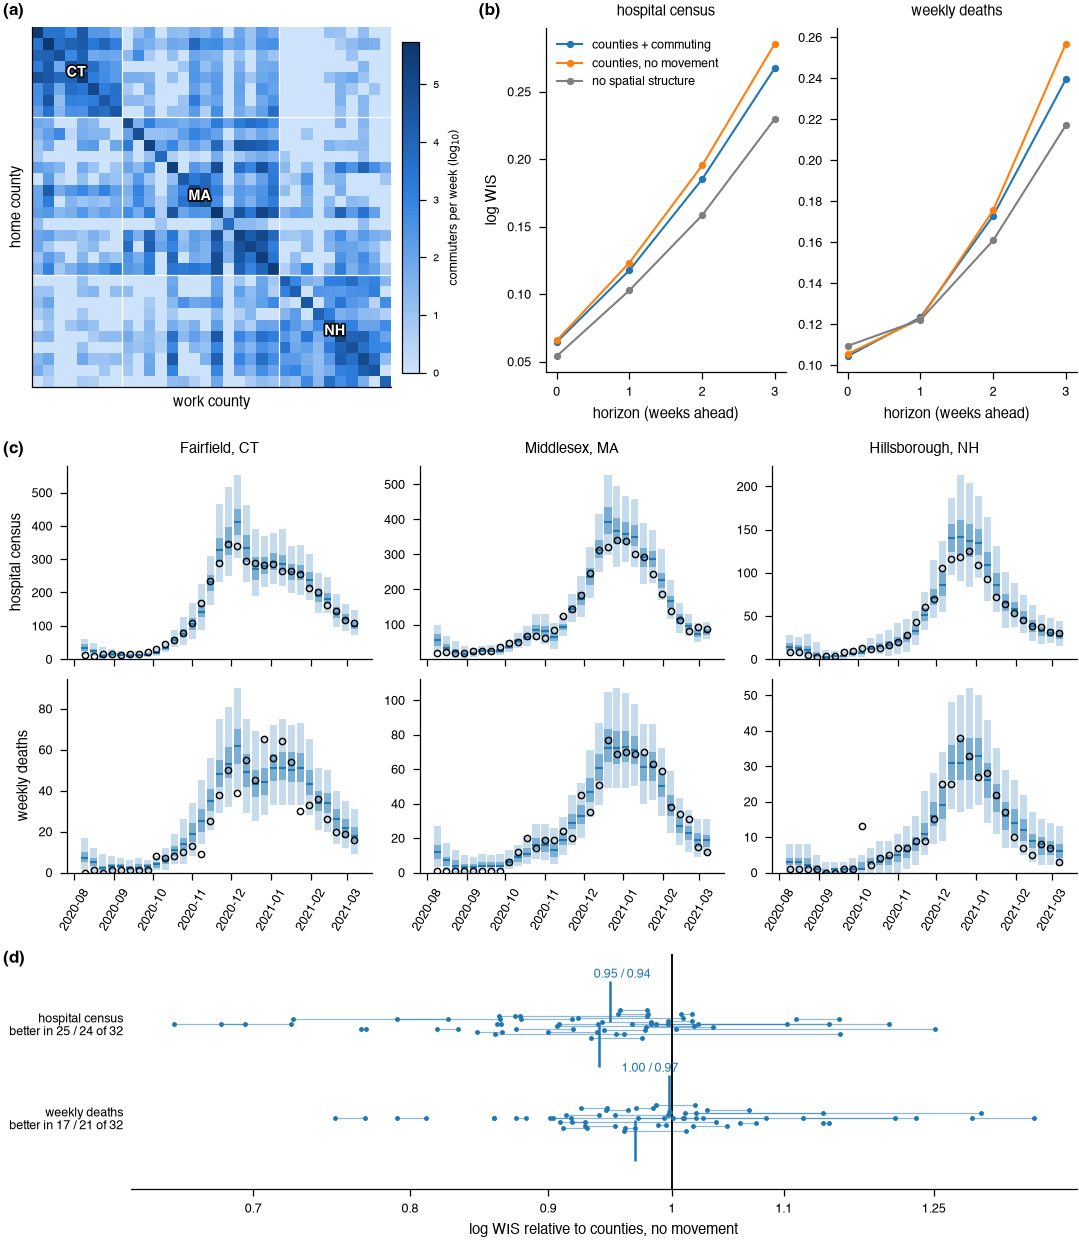

In [7]:
fig = export.figure_3_covid(ev, replicate)
plt.show()

**Supplementary forecast figure**: the movement model's forecasts at its own counties (the
darker shade) and at the three states they are summed into and scored at.

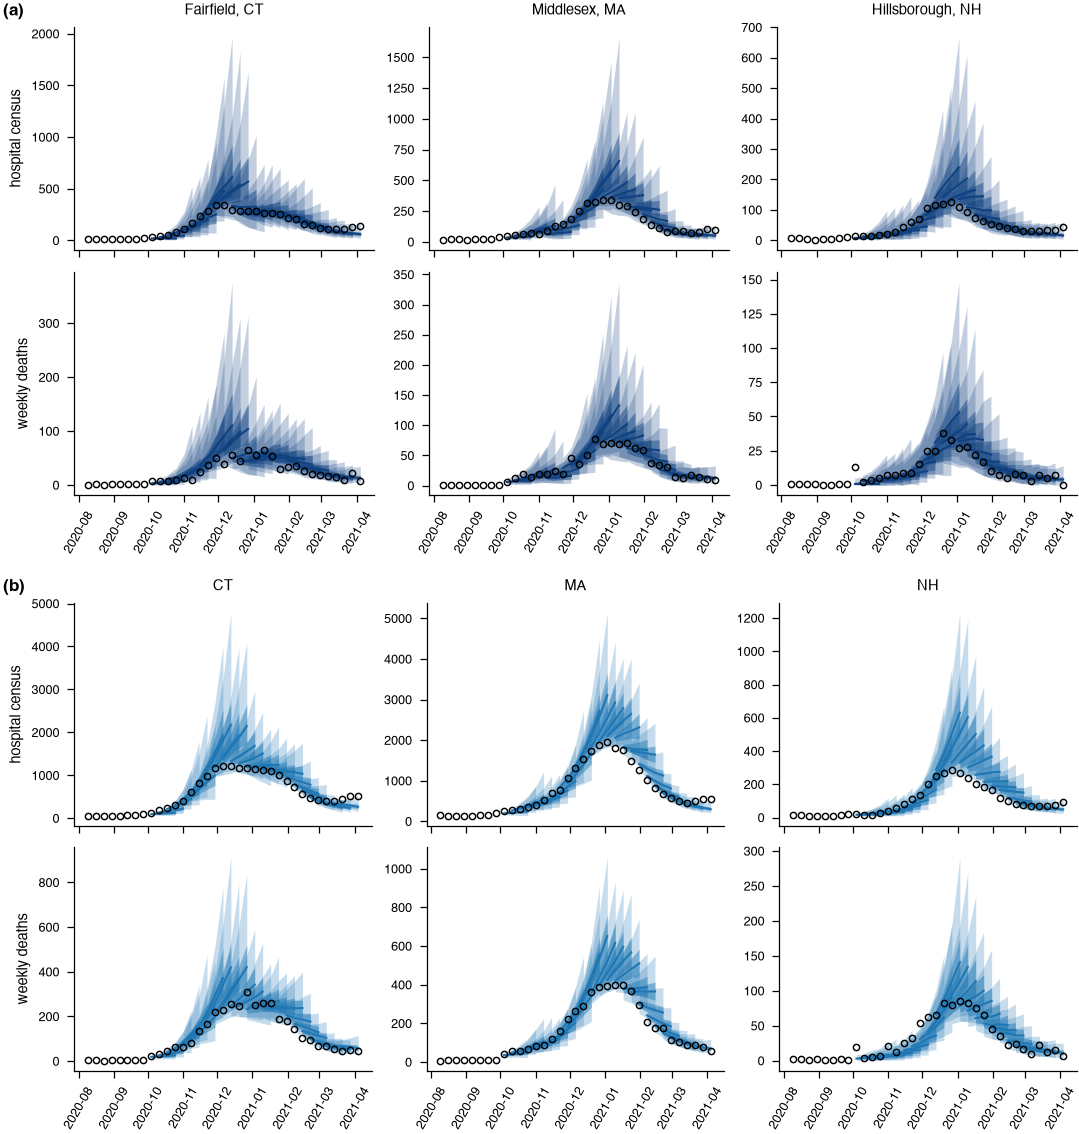

In [8]:
fig = export.figure_s_covid_forecasts(ev)
plt.show()

**Supplementary calibration figure, Demo 2's panels**: coverage of the central intervals
against their nominal level. Summed to states, the county models are overconfident at
longer horizons, while the state model is wide.

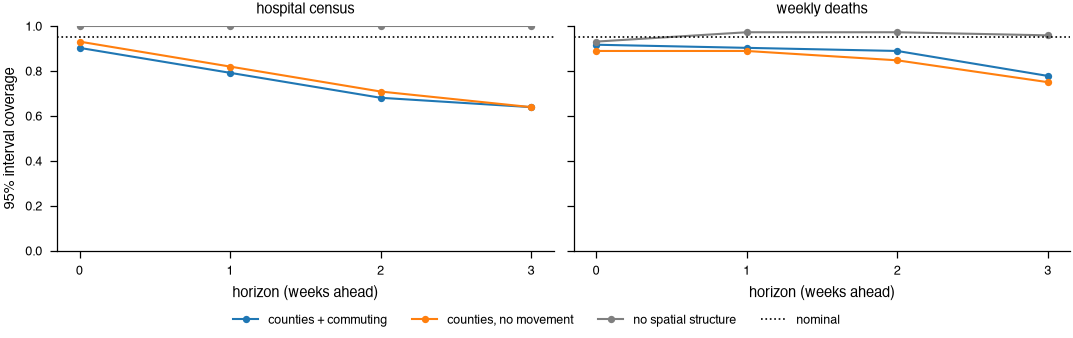

In [9]:
fig = evaluation.figure_calibration(ev, nominal=0.95)
plt.show()